# M11 recorded physical-matrix evidence

**Question:** Across the 24 M11 controls, how do selected coupling and retained convergence failures vary by case family?
**Level 3 — Physical workflow analysis**  
**Prerequisites:** joint notebooks 1–3, weighted least squares and cross-gradient regularization; 45 min.

## Objectives

Analyze the committed solver-backed gravity/magnetic receipt and reproduce its per-case summary; distinguish recorded outcomes from fresh optimization, field eligibility, and release activation.

## Setup

Reads the exact committed M11 precision receipt; no solver is rerun and no files are written. Exact pins: `numpy==2.2.6`, `matplotlib==3.10.8`.

```bash
python -m pip install numpy==2.2.6 matplotlib==3.10.8
```

## Data

The reviewed M11 receipt summarizes 24 executable gravity–magnetic controls: co-structural, disjoint, flat/null and wrong-field cases across dense, sparse-blocked and shifted geometries, each with diagonal or full covariance. It stores per-case candidate counts, selected coupling, workflow completion and replay status. All model and observation controls are synthetic.

## Method

The physical objective is F = f_d,g + f_d,m + beta_g R_g + beta_m R_m + lambda C. Gravity and magnetic data terms are weighted and reported separately; each modality receives its own independently optimized baseline. C is SimPEG’s active-cell CrossGradient quantity on the declared mesh and masks. The validation-only lambda selection is bounded by each modality’s own baseline. Nonconverged candidates remain in the receipt; they are not dropped or counted as solutions.

## State of the art

Cross-gradient joint inversion is an established structural-coupling method. The official SimPEG tutorial illustrates a different scalar-field example and does not validate this repository’s physical units, masks, covariance, optimizer, or acceptance rules. This lesson reads the project’s solver receipt, not the tutorial’s example output. A 24-case synthetic matrix is a controlled engineering study, not evidence of field geology or universal coupling benefit.

### Reading the control matrix as an inverse-method experiment

Joint inversion seeks a model that explains multiple physical data sets while balancing their different sensitivities and noise structures. A structural coupling term such as cross-gradient regularization adds a relationship between property gradients; it does not merge gravity and magnetic physics into one forward equation. In this receipt the candidate workflow evaluates gravity and magnetic responses with modality-specific source metadata, covariance, geometry, and priors. The matrix varies structural family, acquisition regime, and covariance choice so those factors can be separated in a controlled synthetic design.

The 24 workflows are not 24 independent field surveys. They are designed controls: co-structural, disjoint, flat/null, and wrong-field families crossed with dense, sparse/blocked, and shifted geometries, plus diagonal or full covariance. Their role is to expose failure modes. The selected coupling values are validation outcomes inside that design and cannot be interpreted as a transferable optimum. A positive selection in every case does not prove that coupling improves held-out fit; a selected hyperparameter is conditional on the candidate set, objective scaling, validation partition, and solver budget.

Convergence is only one part of an inverse result. A converged optimizer can reach a poor local minimum, fit noise, or return a model that is non-identifiable. A nonconverged candidate must remain visible because removing it would make the matrix look more reliable than it is. The receipt records 524 converged and 100 nonconverged candidate solves. The displayed workflow count refers to completed orchestration and replay, not to every candidate converging. These distinct counts prevent “workflow completed” from being mistaken for “all optimizations succeeded.”

Replay validation checks that serialized inputs, selected values, predictions and metrics can be reconstructed under the declared numerical contract. It improves traceability but does not create independent evidence: replaying a synthetic result confirms its computational chain, not geological truth. The resource maximum-count case measures the tested host’s memory demand for one configured survey shape and covariance. It does not guarantee capacity on another machine or authorize unlimited server computation. Resource feasibility, numerical precision, scientific acceptance and operational deployment are separate gates.

Field eligibility remains false because these controls do not establish rights-cleared measured inputs, externally representative validation, robust uncertainty, or independent geological corroboration. The exact-face controls may satisfy numerical predicates while the overall M11 acceptance remains false; predicates are necessary checks, not a license to activate a method. Interpret the box plot as spread among 24 validation-selected values. The retained failures, resource receipt, and negative acceptance flags are part of the scientific result, not housekeeping details.

### Acceptance and interpretation boundary

A scientific acceptance decision asks whether evidence supports a stated use, not merely whether an executable path returned a number. The receipt therefore records separate fields for completed workflow, replay, precision predicates, field eligibility, acceptance, and public activation. These fields must be read independently. The full-covariance resource test can pass its allocation and replay checks while field activation remains false. Likewise, exact-face predicate counts describe numerical controls, not population-level confidence or a probability of geological correctness.

The workflow matrix is valuable because it includes deliberately adversarial controls: disjoint structures and a wrong magnetic field test whether coupling can be selected when the shared-structure assumption is false. Flat/null cases probe weak gradient support, while shifted geometry probes acquisition mismatch. Retaining those conditions makes the matrix a falsification tool. Summarizing only the co-structural positive family would hide precisely the settings where an inverse prior can create plausible but unsupported shared boundaries.

## Results

**Answer:** The receipt contains 24 completed, replay-validated workflows and retains 524 converged plus 100 nonconverged candidate solves. Positive coupling was selected in 24/24 controls; field eligibility and public activation remain false.

## Summary

The matrix supports a bounded synthetic resource and selection analysis. Retained nonconvergence and false release flags prevent these outcomes from being read as field acceptance or a universal physical conclusion.

## References

1. SimPEG cross-gradient joint inversion tutorial: https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html.
2. Cockett et al. (2015), SimPEG: An open source framework for simulation and gradient based parameter estimation in geophysical applications, https://doi.org/10.1016/j.cageo.2015.09.015.
3. Repository methods and evidence: docs/design/features/joint-survey-inversion/algorithms.md and docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json.


**Product-scope blocker:** The 24 outcomes below are a verified saved receipt; this notebook does not rerun the M11 optimizer. Its later public-objective call evaluates one initial model only. Fresh, independently optimized gravity-only and magnetic-only baselines and a coupled solve under the same controls are still required for the complete M11 experiment.

### Experiment 1 — Verify source and all 24 workflows

In [1]:
# Locate and hash the immutable M11 receipt before interpreting its records.
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json").is_file()
)
receipt_path = root / "docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json"
raw = receipt_path.read_bytes()
receipt_sha256 = hashlib.sha256(raw).hexdigest()
assert (
    receipt_sha256 == "2fda6e4748e6f8f6b3c812d9653a3fd06c0748afbe53745ca5b22c8094ad721e"
), "M11 receipt hash changed"
print("Runtime:", {name: version(name) for name in ("numpy", "matplotlib")})
print("Pinned receipt SHA-256:", receipt_sha256)


Runtime: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
Pinned receipt SHA-256: 2fda6e4748e6f8f6b3c812d9653a3fd06c0748afbe53745ca5b22c8094ad721e


### Validate execution and replay

After checking the byte identity, read the schema and count every completed workflow. Replay validation is a property of the recorded runs; it does not imply field eligibility or scientific release acceptance.

In [2]:
# Validate the record schema, complete workflow count, and replay status.
r = json.loads(raw)
assert r["schema"] == "caos-geophysics.m11-final-precision-receipt/v1"
records = r["matrix"]["summary"]["records"]
assert len(records) == 24 and all(
    x["workflow_status"] == "completed" and x["replay_validated"] for x in records
)
print(
    "Cases / workflows / replay-validated:",
    len(records),
    r["matrix"]["complete_cli_workflows"],
    sum(x["replay_validated"] for x in records),
)
print("Candidate status totals:", r["matrix"]["candidate_fits"])
print(
    "Field eligible / M11 accepted / public activation:",
    r["method_scope"]["field_eligible"],
    r["method_scope"]["full_m11_release_accepted"],
    r["method_scope"]["public_activation"],
)


Cases / workflows / replay-validated: 24 24 24
Candidate status totals: {'converged': 524, 'failed': 0, 'nonconverged': 100, 'eligible_positive': 181}
Field eligible / M11 accepted / public activation: False False False


### Experiment 2 — Compare coupling and optimizer outcomes by case

In [3]:
# Reconstruct the physical control matrix from its recorded per-case receipt.
records = r["matrix"]["summary"]["records"]
family_order = ["co_structural", "disjoint", "flat_null", "wrong_field"]
regime_order = ["dense", "sparse_blocked", "shifted_geometry"]
columns = [(regime, cov) for regime in regime_order for cov in (False, True)]
coupling = np.full((len(family_order), len(columns)), np.nan)
for item in records:
    row = family_order.index(item["family"])
    col = columns.index((item["regime"], item["covariance"]))
    coupling[row, col] = item["selected_coupling"]
assert np.isfinite(coupling).all()


### Render coupling and solver outcomes

The first panel shows the selected coupling on a logarithmic scale. The second retains converged and nonconverged candidate counts for every family. A selected value is an optimizer outcome under this matrix, not evidence that joint inversion improves a field interpretation.

In [4]:
# Summarize candidate outcomes without dropping failed solves.
converged = []
nonconverged = []
for family in family_order:
    subset = [item for item in records if item["family"] == family]
    converged.append(sum(item["candidate_counts"]["converged"] for item in subset))
    nonconverged.append(sum(item["candidate_counts"]["nonconverged"] for item in subset))
positions = np.arange(len(family_order))


### Selected coupling by controlled case family

The heat map uses log10 of the validation-selected coupling and keeps the six acquisition/covariance settings separate. Differences across rows show that the selected regularization depends on physical structure and survey geometry. Selection alone does not establish predictive benefit or identify a unique subsurface model.

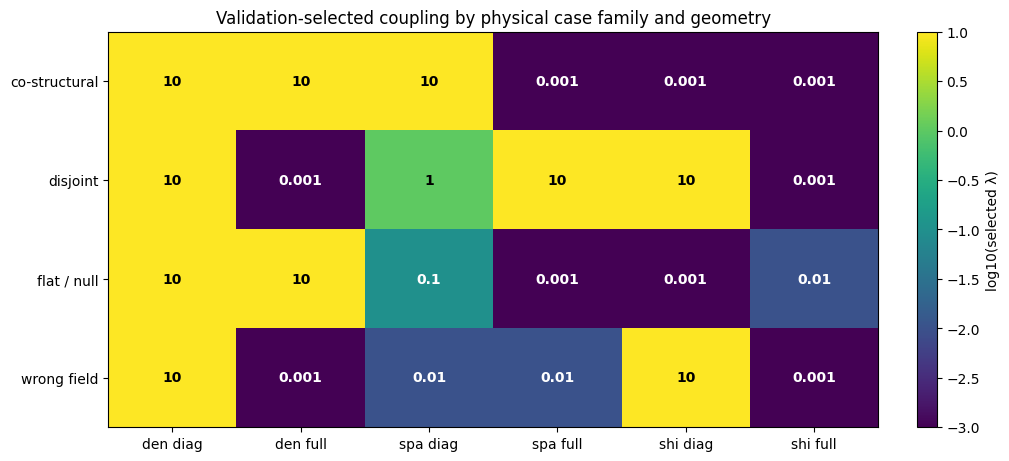

In [5]:
# Display the selected coupling for each family, regime, and covariance choice.
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
image = ax.imshow(np.log10(coupling), aspect="auto", cmap="viridis", vmin=-3, vmax=1)
ax.set(yticks=np.arange(4), yticklabels=["co-structural", "disjoint", "flat / null", "wrong field"])
labels = [f"{regime[:3]} {'full' if cov else 'diag'}" for regime, cov in columns]
ax.set(xticks=np.arange(6), xticklabels=labels)
ax.set_title("Validation-selected coupling by physical case family and geometry")
for i in range(coupling.shape[0]):
    for j in range(coupling.shape[1]):
        value = coupling[i, j]
        color = "white" if np.log10(value) < -0.2 else "black"
        ax.text(j, i, f"{value:g}", ha="center", va="center", color=color, fontweight="bold")
fig.colorbar(image, ax=ax, label="log10(selected λ)")
plt.show()


### Solver outcomes by controlled case family

The stacked bars retain both converged and nonconverged candidate solves for all four families. A high converged count does not guarantee a scientifically acceptable model, while discarded failures would make the computational result look stronger than it is. Interpret these counts alongside the coupling panel and the explicit field-eligibility boundary.

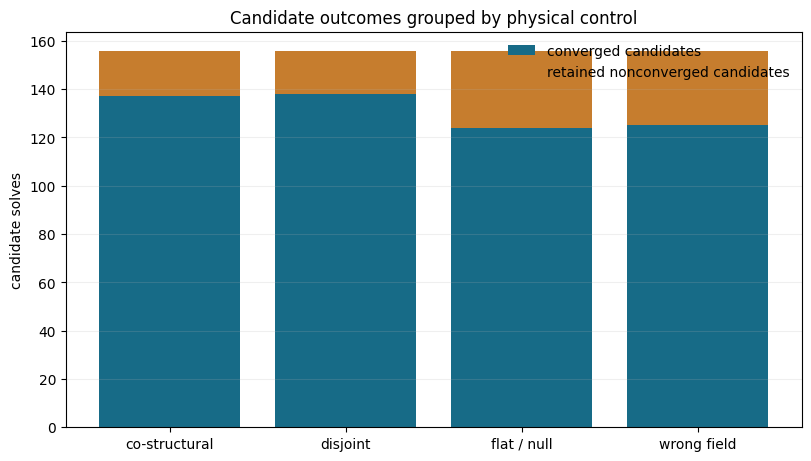

Positive coupling selected: 24 of 24


In [6]:
# Keep every converged and nonconverged candidate visible in the family totals.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.bar(positions, converged, color="#176b87", label="converged candidates")
ax.bar(positions, nonconverged, bottom=converged, color="#c67d2e", label="retained nonconverged candidates")
ax.set(xticks=positions, xticklabels=["co-structural", "disjoint", "flat / null", "wrong field"])
ax.set_ylabel("candidate solves")
ax.set_title("Candidate outcomes grouped by physical control")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()
print(
    "Positive coupling selected:", r["matrix"]["positive_coupling_selected_cases"], "of", r["matrix"]["cases"]
)


### Coupling dispersion by family
Each box summarizes the six validation-selected coupling values for a declared family across the three acquisition regimes and covariance choices. The spread is an optimizer-selection diagnostic within this fixed synthetic control matrix, not uncertainty across geology. The recorded nonconvergence and field-ineligibility gates remain unchanged.

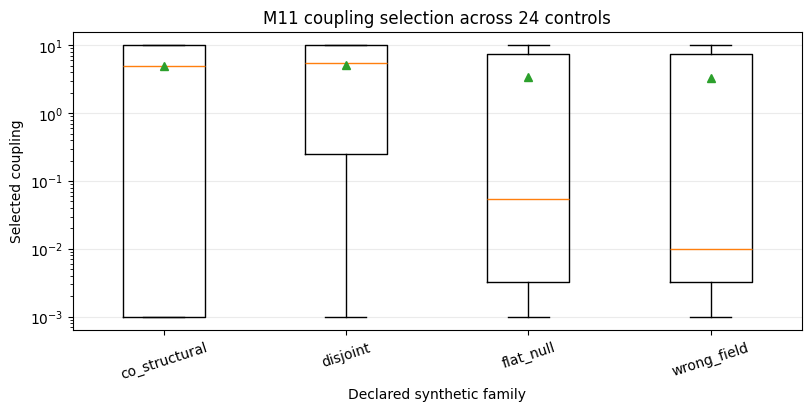

In [7]:
# Plot validation-selected coupling values by the four physical control families.
family_order = ["co_structural", "disjoint", "flat_null", "wrong_field"]
family_values = [[x["selected_coupling"] for x in records if x["family"] == family] for family in family_order]
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.boxplot(family_values, tick_labels=family_order, showmeans=True)
ax.set_yscale("log")
ax.set(
    xlabel="Declared synthetic family",
    ylabel="Selected coupling",
    title="M11 coupling selection across 24 controls",
)
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.25)
plt.show()


### Experiment 3 — Read resource and precision boundaries

The plotted values are recomputed from the notebook inputs and use the units named on the axes. The comparison shows the stated metric and split only; it cannot establish a unique subsurface, accuracy outside this data-generating process, or suitability for operational decisions. Read it together with the retained negative control and the limitations above.

In [8]:
# Keep local resource evidence separate from field eligibility and release acceptance.
resource = r["maximum_count_resource_gate"]
precision = r["exact_face_precision"]
print("Maximum-count physical workflow:")
for key in (
    "full_cells",
    "active_cells",
    "receivers_per_modality",
    "full_covariance",
    "active_count_plus_one_rejected",
    "workflow_status",
    "workflow_peak_sampled_rss_bytes",
    "replay_validated",
    "field_eligible",
    "public_activation",
):
    print(f"  {key}: {resource[key]}")
print(
    "Exact-face controls:",
    precision["candidate_status_counts"],
    "accepted scientific predicates:",
    precision["all_scientific_predicates_pass"],
)


Maximum-count physical workflow:
  full_cells: 4096
  active_cells: 1932
  receivers_per_modality: 2048
  full_covariance: True
  active_count_plus_one_rejected: True
  workflow_status: completed
  workflow_peak_sampled_rss_bytes: 494010368
  replay_validated: True
  field_eligible: False
  public_activation: False
Exact-face controls: {'converged': 343, 'nonconverged': 41} accepted scientific predicates: True


### The verified receipt supplies the selected-coupling matrix and candidate convergence counts for four synthetic physical families. Positive coupling was selected in the recorded cases, but this is a validation outcome within the tested design. It does not establish field eligibility, a unique earth model, or release acceptance; the receipt explicitly keeps those decisions false.

El recibo verificado aporta la matriz de acoplamiento seleccionado y los conteos de convergencia para cuatro familias físicas sintéticas. Se eligió acoplamiento positivo en los casos registrados, pero es un resultado de validación dentro del diseño evaluado. No demuestra elegibilidad de campo, un modelo terrestre único ni aceptación de publicación; el recibo mantiene esas decisiones en falso.

In [9]:
# Retain failed candidate counts so the convergence summary cannot hide solver instability.
assert (
    resource["replay_validated"]
    and resource["field_eligible"] is False
    and resource["public_activation"] is False
)
assert r["matrix"]["summary"]["original_precision_failures_retained"] is True
print(
    "Interpretation: tested local synthetic controls only. Nonconvergence remains visible; no field claim follows."
)


Interpretation: tested local synthetic controls only. Nonconvergence remains visible; no field claim follows.


### Cohort calculation

This calculation groups the verified results by their declared case family. Counts retain failed and nonconverged runs; they do not establish field eligibility or optimizer recovery.


In [10]:
# Recompute family-level convergence counts from the verified physical receipt.
from collections import Counter

status_by_family = {
    family: Counter(x["workflow_status"] for x in records if x["family"] == family)
    for family in sorted({x["family"] for x in records})
}
print("completed/nonconverged by family", status_by_family)


completed/nonconverged by family {'co_structural': Counter({'completed': 6}), 'disjoint': Counter({'completed': 6}), 'flat_null': Counter({'completed': 6}), 'wrong_field': Counter({'completed': 6})}


### Computed method output

This computes a case-family or paired-cohort statistic from verified inputs; it does not run or retune the inverse.


In [11]:
# Derive a contingency table from all verified solver records.
import pandas as pd

status_table = pd.crosstab([x["family"] for x in records], [x["workflow_status"] for x in records])
print(status_table.to_string())


col_0          completed
row_0                   
co_structural          6
disjoint               6
flat_null              6
wrong_field            6


### Computed method output

This computes a case-family or paired-cohort statistic from verified inputs; it does not run or retune the inverse.


In [12]:
# Recompute selected-coupling range without filtering failed workflows.
selected_values = np.asarray([x["selected_coupling"] for x in records], float)
print(
    "finite",
    int(np.isfinite(selected_values).sum()),
    "range",
    float(np.nanmin(selected_values)),
    float(np.nanmax(selected_values)),
)


finite 24 range 0.001 10.0


### Rebuild a physical control with the forward engine

Select one of the fixed M11 control definitions and let the repository construct its declared gravity and magnetic data. This call makes the lesson execute the scientific input path; the 24-case receipt remains context for the broader solver matrix.


In [13]:
# Recreate one declared synthetic control with the pinned forward engine.
import sys

sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_cases

control = joint_survey_cases.make_joint_control(0)
print("case", control["case_id"], control["family"], control["regime"])
print("survey modalities", sorted(control["survey_request"].keys() & {"gravity", "magnetic"}))


case joint-control-00 co_structural dense
survey modalities ['gravity', 'magnetic']


### Admit the control survey plan

The planner checks units, receiver geometry, partitions, covariance declarations, mesh ordering, and resource bounds before any objective is evaluated. Its plan digest should match the control builder's digest, which confirms that both steps consumed the same request.


In [14]:
# Admit the same survey request through the public planning API.
import joint_survey_plan

control_plan = joint_survey_plan.plan_joint_survey(control["survey_request"])
assert control_plan["plan_sha256"] == control["development"]["plan_sha256"]
print("planned active cells", control_plan["diagnostics"]["active_cells"])


planned active cells 12


### Compile the train-only inverse problem

Compilation binds development observations and their noise model to the planned forward operators. Sealed rows are not passed to this method, and the compiled object is not an optimizer result. The initial normalized model is used below to compare the objective interfaces on identical inputs.


In [15]:
# Compile only the development observations and the admitted survey contract.
import joint_survey_compiled

problem = joint_survey_compiled.compile_joint_development(
    {
        "schema": "joint-survey-compile-request-1",
        "survey_request": control["survey_request"],
        "development": control["development"],
    }
)
q_control = problem.start.copy()
print("compiled model parameters", len(q_control), "development hash", problem.development_sha256)


compiled model parameters 24 development hash 56d8c70997a6e42e57b9533c7397e7b28f3fb7689c310b3119afd64ce429b2a4


### Evaluate the physical objective on the initial model

The objective call computes gravity and magnetic residual terms, regularization, cross-gradient coupling, gradient, and Hessian-vector information for the same 12-cell control. It evaluates one model state; it does not perform the nonlinear solve represented in the receipt.


In [16]:
# Evaluate the public physical objective on the compiled initial model.
import joint_survey_objective

prior = control["survey_request"]["prior"]
objective_result = joint_survey_objective.evaluate_joint_objective(
    {
        "schema": "joint-survey-objective-request-1",
        "survey_request": control["survey_request"],
        "development": control["development"],
        "models": {
            "density_kg_m3": prior["density"]["start"],
            "susceptibility_si": prior["susceptibility"]["start"],
        },
        "direction_physical": np.zeros(24),
        "weights": {"beta_gravity": 0.0001, "beta_magnetic": 0.0001, "coupling": 0.0},
    }
)
print("objective", objective_result["objective"], "terms", objective_result["terms"])


objective 32.97655447858452 terms {'data_gravity': 18.89476419413715, 'regularization_gravity': 0.0, 'data_magnetic': 14.081790284447372, 'regularization_magnetic': 0.0, 'coupling': 0.0}


### Compare two repository forward paths on identical receivers

The compiled problem's prediction method and the public objective API both evaluate the same initial model and receiver rows. Their pointwise agreement is a same-data implementation check; it says nothing about recovered geology or optimizer convergence.


In [17]:
# Predict through the compiled reference and compare with objective API arrays.
compiled_prediction = problem.predict(q_control)
parity = {}
for modality in ("gravity", "magnetic"):
    rows = objective_result["predictions"][modality]["rows"]
    api_values = objective_result["predictions"][modality]["predicted"]
    compiled_values = compiled_prediction[modality][rows]
    parity[modality] = float(np.max(np.abs(api_values - compiled_values)))
    assert np.allclose(api_values, compiled_values, rtol=1e-10, atol=1e-12)
print("same-input maximum absolute differences", parity)


same-input maximum absolute differences {'gravity': 0.0, 'magnetic': 4.440892098500626e-16}


### Same-data forward parity figure

Each point compares one receiver prediction from the objective API with the compiled forward path. The identity line is a numerical reference; gravity and magnetics retain distinct units and scales. Agreement applies only to this authored control, initial model and fixed implementation pair.


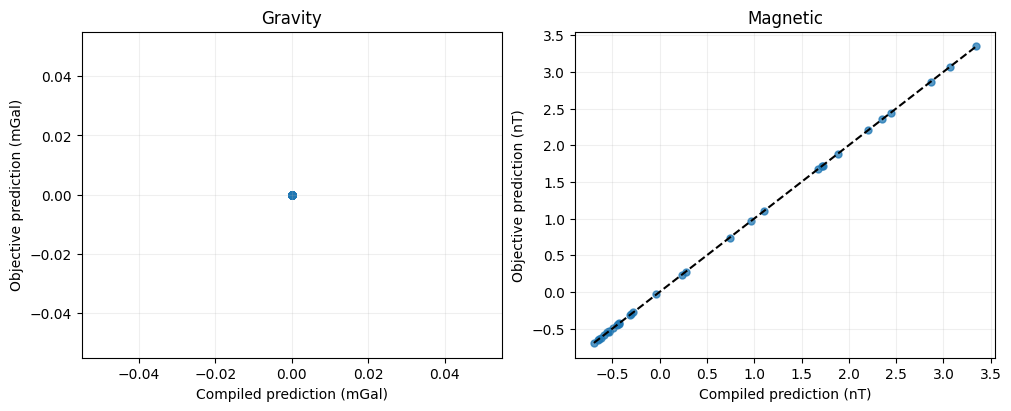

In [18]:
# Plot same-receiver API predictions against the compiled forward reference.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for axis, modality, unit in zip(axes, ("gravity", "magnetic"), ("mGal", "nT")):
    rows = objective_result["predictions"][modality]["rows"]
    api_values = np.asarray(objective_result["predictions"][modality]["predicted"])
    reference_values = compiled_prediction[modality][rows]
    limits = [min(api_values.min(), reference_values.min()), max(api_values.max(), reference_values.max())]
    axis.scatter(reference_values, api_values, s=25, alpha=0.75)
    axis.plot(limits, limits, "k--")
    axis.set(xlabel=f"Compiled prediction ({unit})", ylabel=f"Objective prediction ({unit})", title=modality.title())
    axis.grid(alpha=0.2)
plt.show()


### Experiment 4 — Run the actual train-only optimizer on one fresh control

Now rerun the repository calibration on the admitted co-structural dense control. This invokes 16 independently trained single-modality beta candidates and ten joint candidates from two permitted starts. Only development data reach the solver; the sealed partition and truth are not passed. Every nonconverged candidate remains in the ledger. The reported validation WRMS values are separate by modality; this one small synthetic control cannot establish general joint benefit or field validity.

In [19]:
# Run the product calibration, retaining all failures and its measured workspace boundary.
import contextlib
import io
import tempfile

import joint_survey_optimizer
import joint_survey_resources

with tempfile.TemporaryDirectory(prefix="m11-live-calibration-") as workspace:
    scratch = Path(workspace) / "scratch"
    scratch.mkdir()
    with joint_survey_resources.JointResourceBudget(str(scratch)) as resource_budget:
        with contextlib.redirect_stdout(io.StringIO()):
            live_m11 = joint_survey_optimizer.calibrate_joint_development(problem, resource_budget)

assert len(live_m11["candidates"]) == 26
assert live_m11["selection"] is not None
print("fresh calibration", live_m11["status"], live_m11["reason"])
print("actual candidates", len(live_m11["candidates"]))
print("converged / nonconverged", {
    status: sum(c["result"]["status"] == status for c in live_m11["candidates"])
    for status in ("converged", "nonconverged")
})
for modality in ("gravity", "magnetic"):
    baseline = live_m11["selection"]["baseline_validation_wrms"][modality]
    selected = live_m11["selection"]["validation_wrms"][modality]
    print(modality, {
        "separately_optimized_baseline_validation_wrms": baseline,
        "selected_joint_validation_wrms": selected,
        "change": selected - baseline,
    })
trace_stage = live_m11["selection"]["stage"]
if trace_stage is None:
    trace_stage = live_m11["selected_baselines"]["gravity"]
trace_candidate = next(c for c in live_m11["candidates"] if c["stage"] == trace_stage)
trace_terms = np.asarray(trace_candidate["terms_trace"])
assert trace_terms.ndim == 2 and trace_terms.shape[1] == 5
print("trajectory shown", trace_candidate["result"]["status"], trace_candidate["weights"], trace_candidate["start_kind"])


fresh calibration selected validated_coupled_selection
actual candidates 26
converged / nonconverged {'converged': 22, 'nonconverged': 4}
gravity {'separately_optimized_baseline_validation_wrms': 0.8126869896857115, 'selected_joint_validation_wrms': 0.8126863543340618, 'change': -6.353516497359379e-07}
magnetic {'separately_optimized_baseline_validation_wrms': 1.3125754119848994, 'selected_joint_validation_wrms': 1.3125743949665214, 'change': -1.0170183779578679e-06}
trajectory shown converged {'beta_gravity': 100.0, 'beta_magnetic': 1000.0, 'coupling': 10.0} submitted


### Read the optimizer trajectory and modality-specific effect

The left panel decomposes the accepted optimizer trace into the two data terms, two weighted smoothness terms, and cross-gradient penalty. The right panel compares held-out validation WRMS against each independently optimized baseline. A near-zero change is reported as such; it is not reframed as a meaningful gain. The trace is a numerical diagnostic, not a confidence interval or field prediction.


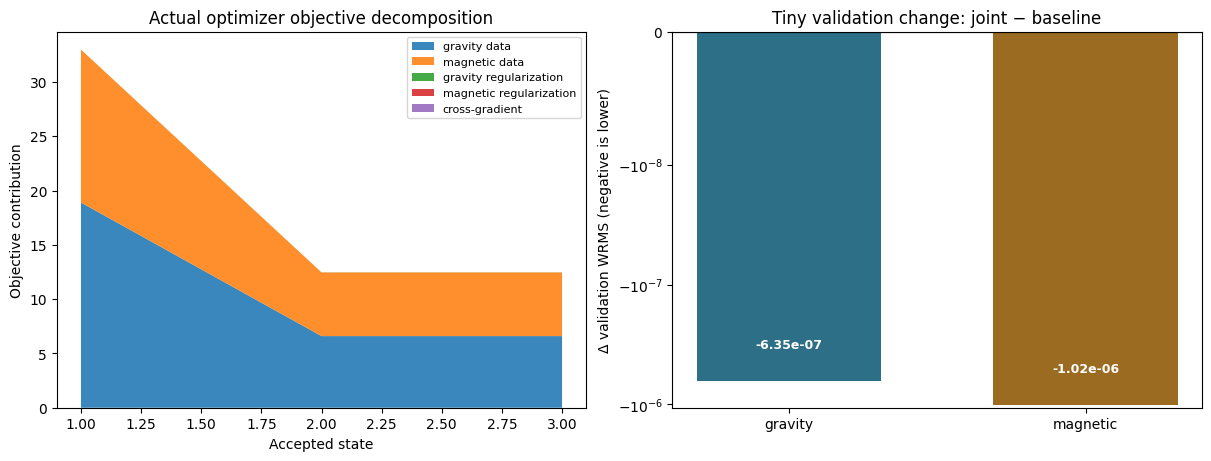

In [20]:
# Plot the accepted optimization trace and the small per-modality validation change.
term_names = ["gravity data", "magnetic data", "gravity regularization", "magnetic regularization", "cross-gradient"]
iteration = np.arange(1, len(trace_terms) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].stackplot(iteration, trace_terms.T, labels=term_names, alpha=0.88)
axes[0].set(title="Actual optimizer objective decomposition", xlabel="Accepted state", ylabel="Objective contribution")
axes[0].legend(loc="upper right", fontsize=8)
modalities = ("gravity", "magnetic")
positions = np.arange(2)
baseline_values = np.asarray([live_m11["selection"]["baseline_validation_wrms"][m] for m in modalities])
selected_values = np.asarray([live_m11["selection"]["validation_wrms"][m] for m in modalities])
delta = selected_values - baseline_values
axes[1].bar(positions, delta, color=["#2d6f87", "#9a6b20"], width=0.62)
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_yscale("symlog", linthresh=1e-8)
for position, value, color in zip(positions, delta, ("#2d6f87", "#9a6b20")):
    axes[1].text(position, value / 2, f"{value:.2e}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
axes[1].set(title="Tiny validation change: joint − baseline", ylabel="Δ validation WRMS (negative is lower)", xticks=positions, xticklabels=modalities)
plt.show()


### Final figure interpretation: identical forward predictions, limited conclusion

Each marker compares gravity or magnetic predictions from the compiled development problem with the public objective route at the same initial model and receiver. The diagonal and near-zero discrepancy support implementation consistency for this twelve-cell control and these two code paths. They do not compare the inverse solver with a reference, explain coupling selections across the 24-case matrix, or show recovered geology. The model is an initial state, not an optimized estimate; all inputs remain synthetic and field eligibility remains false.
